# Homework 1: Learning Nemi with Attention

**Course:** NLP Fall 2026  
**Designer:** Danial Parnian

**Name:** Negin Moradi  

Nemi is a small invented language. Here are three translations:

`the fox sees the bird` → `dax mip luma`  
`the red fox sees the blue bird` → `dax vek mip sul luma`  
`the fox sees the bird near the tree` → `dax mip tem na luma`

You will build the attention components of an encoder–decoder Transformer, train a translator, and test how it combines familiar words in new sentences.

**Grading:** causal mask 5, attention 15, split/merge 5 each, multi-head attention 10, decoder block 15, language extension 15, oral explanation 30.


## 1. Meet the language

The JSON file contains the vocabulary, training and validation data, and two test sets. Both test sets contain new sentences. In the second, one adjective–noun combination in each sentence was excluded from training; the individual words were still used elsewhere. Both tests have the same sentence-length and location-phrase distributions. The new location phrase puts its Nemi location word before `na`, as the third example above shows.

Keep `Notebook2_Translation_Data.json` beside the notebook. On Kaggle, attach it as an input dataset and enable a GPU. The cells below use the same file in either location.


In [1]:
import copy
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

data_path = Path('Notebook2_Translation_Data.json')
if not data_path.exists():
    data_path = next(Path('/kaggle/input').rglob(data_path.name))
with data_path.open(encoding='utf-8') as file:
    data = json.load(file)
splits = data['splits']
print('Device:', device)
display(pd.DataFrame([(name, len(rows)) for name, rows in splits.items()],
                     columns=['Split', 'Sentences']))


Device: cuda


,Split,Sentences
0,train,16000
1,validation,1400
2,test_familiar,1800
3,test_new_pairs,1800


In [2]:
lexicon = data['lexicon']
vocabulary_table = {
    kind.title(): pd.Series([f'{english} → {nemi}' for english, nemi in entries.items()])
    for kind, entries in lexicon.items()
}
display(pd.DataFrame(vocabulary_table).fillna(''))
display(pd.DataFrame(splits['train'][:4]).rename(columns={'source': 'English', 'target': 'Nemi'}))

PAD, BOS, EOS = 0, 1, 2
special = ['<pad>', '<bos>', '<eos>']
def build_vocab(rows):
    source_words = sorted({word for row in rows for word in row['source'].split()})
    target_words = sorted({word for row in rows for word in row['target'].split()})
    source_vocab, target_vocab = special + source_words, special + target_words
    return (source_vocab, target_vocab,
            {word: i for i, word in enumerate(source_vocab)},
            {word: i for i, word in enumerate(target_vocab)})


src_vocab, tgt_vocab, src_ids, tgt_ids = build_vocab(splits['train'])


def collate(rows):
    source = [torch.tensor([src_ids[w] for w in row['source'].split()]) for row in rows]
    target = [torch.tensor([BOS, *[tgt_ids[w] for w in row['target'].split()], EOS]) for row in rows]
    src = pad_sequence(source, batch_first=True, padding_value=PAD)
    full_target = pad_sequence(target, batch_first=True, padding_value=PAD)
    return src, full_target[:, :-1], full_target[:, 1:]


,Nouns,Verbs,Adjectives,Locations,Prepositions
0,fox → dax,sees → luma,red → vek,tree → tem,near → na
1,bird → mip,chases → nora,blue → sul,house → ush,
2,cat → nesh,follows → siva,green → gami,river → rav,
3,dog → vok,finds → peko,small → tik,market → ket,
4,rabbit → tib,likes → rali,big → boru,,
5,wolf → zur,helps → tenu,quiet → nali,,
6,bear → bam,,,,
7,horse → kel,,,,
8,mouse → fim,,,,
9,duck → pon,,,,


,English,Nemi
0,the blue duck helps the blue mouse,pon sul fim sul tenu
1,the fox likes the green horse near the river,dax kel gami rav na rali
2,the big dog finds the big wolf near the tree,vok boru zur boru tem na peko
3,the small bear chases the red rabbit,bam tik tib vek nora


## 2. The two streams

The encoder reads the English source. During training, the decoder reads the correct Nemi sentence shifted right: it starts with `<bos>` and predicts one position ahead, ending with `<eos>`. This is **teacher forcing**. A single forward pass scores every target position.

Padding makes the sentences in a batch equally long. We exclude padding keys from attention and padding labels from the loss.


In [3]:
source, decoder_input, labels = collate(splits['train'][:2])
for name, row, vocabulary in [
    ('Source', source[0], src_vocab),
    ('Decoder input', decoder_input[0], tgt_vocab),
    ('Labels', labels[0], tgt_vocab)
]:
    print(f'{name:14s}:', ' '.join(vocabulary[i] for i in row.tolist()))


Source        : the blue duck helps the blue mouse <pad> <pad>
Decoder input : <bos> pon sul fim sul tenu <eos>
Labels        : pon sul fim sul tenu <eos> <pad>


## 3. Which positions are visible?

Rows are queries; columns are keys. We use **`True` for a visible key** throughout this notebook.

| Attention | Queries | Keys and values | Visibility |
|---|---|---|---|
| Encoder self-attention | English states | English states | All source words |
| Decoder self-attention | Nemi states | Nemi states | Current and earlier positions |
| Cross-attention | Decoder states | Encoder output | All source words |

**TODO 1:** Return a boolean `[T, T]` causal mask, including the diagonal. Query 1 may read keys 0 and 1. We add the padding mask separately.


In [4]:
def make_causal_mask(length, device=None):
    """Return [T, T], with True exactly where key_position <= query_position."""
    positions = torch.arange(length, device=device) # creating tensor([0, 1, 2, 3, ..., length-1])
    return positions[:, None] >= positions[None, :] # compares every query position with every key position


In [5]:
mask = make_causal_mask(4)
assert mask.dtype == torch.bool
assert torch.equal(mask, torch.tensor([
    [1, 0, 0, 0], [1, 1, 0, 0], [1, 1, 1, 0], [1, 1, 1, 1]
], dtype=torch.bool))
print(mask.int())


tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)


## 4. Scores become weighted information

A query describes what a position is looking for. Each key determines how well another position matches; its value carries the information to read.

$$A=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right),\qquad O=AV.$$

Scaling keeps dot products from growing too large with head width. Softmax runs over **keys**, so each query gets weights that sum to one.

**TODO 2:** Implement the computation. Set blocked scores to `-inf` before softmax. `allowed_mask` is `[Tq, Tk]`; `key_visible` is `[B, Tk]` and excludes padding. Either may be `None`. Our batches always leave at least one visible key per query.


In [6]:
def attention(q, k, v, allowed_mask=None, key_visible=None):
    """Inputs [B, H, Tq/Tk, D]; return output and weights [B, H, Tq, Tk]."""
    numerator = q @ k.transpose(-2, -1) # transpose only the last two dimensions of k
    d_k = q.shape[-1]
    score = numerator / math.sqrt(d_k)

    if allowed_mask is not None:
        score = score.masked_fill(
            ~allowed_mask[None, None, :, :],
            float('-inf')
        ) # positions where the mask is False become -inf

    if key_visible is not None:
        score = score.masked_fill(
            ~key_visible[:, None, None, :],
            float('-inf')
        )

    weights = torch.softmax(score, dim=-1) # dim=-1 means the final dimension, which is the key dimension
    output = weights @ v # the weighted combination of the values
    
    return output, weights


In [7]:
q = torch.tensor([[[[1., 0.]]]])
k = torch.tensor([[[[1., 1.], [0., 1.]]]])
v = torch.eye(2)[None, None]
out, weights = attention(q, k, v)
assert torch.allclose(out.flatten(), torch.tensor([0.6698, 0.3302]), atol=1e-4)
print('One query, two keys:', weights.flatten().tolist())

q = torch.randn(2, 2, 4, 8, requires_grad=True)
k = torch.randn(2, 2, 4, 8, requires_grad=True)
v = torch.randn(2, 2, 4, 6, requires_grad=True)
visible = torch.tensor([[1, 1, 1, 0], [1, 1, 1, 1]], dtype=torch.bool)
out, weights = attention(q, k, v, make_causal_mask(4), visible)
assert out.shape == (2, 2, 4, 6)
assert torch.allclose(weights.sum(-1), torch.ones(2, 2, 4))
assert (weights[..., torch.triu(torch.ones(4, 4, dtype=torch.bool), diagonal=1)] == 0).all()
assert (weights[0, :, :, 3] == 0).all()
out.square().sum().backward()
assert all(x.grad is not None and x.grad.abs().sum() > 0 for x in (q, k, v))


One query, two keys: [0.6697615385055542, 0.3302384614944458]


## 5. Give each head its own features

Multi-head attention divides the projected features into separate heads. With width 96 and four heads, each head compares positions using 24 features.

**TODO 3:** Convert `[B, T, C]` to `[B, H, T, C/H]`. Split the feature axis into heads, then move the head axis before the sequence axis. Keep token and feature order unchanged.


In [8]:
def split_heads(x, n_heads):
    """[B, T, C] -> [B, H, T, C/H]. C is divisible by H."""
    B, T, C = x.shape

    x = x.reshape(B, T, n_heads, C // n_heads) # divide the feature dimension into separate heads ([B, T, H, D])
    x = x.transpose(1, 2) # swap dimensions 1 and 2

    return x


**TODO 4:** Undo the split: `[B, H, T, D]` becomes `[B, T, H*D]`. Concatenate the heads in their original order; do not average them.


In [9]:
def merge_heads(x):
    """[B, H, T, D] -> [B, T, H*D]."""
    B, H, T, D = x.shape

    x = x.transpose(1, 2) # # swap dimensions 1 and 2 ([B, T, H, D])
    x = x.contiguous().reshape(B, T, H * D)

    return x


In [10]:
x = torch.arange(2 * 5 * 24).reshape(2, 5, 24)
heads = split_heads(x, 4)
assert heads.shape == (2, 4, 5, 6)
assert torch.equal(heads[:, 1], x[:, :, 6:12])
assert torch.equal(merge_heads(heads), x)
print(f'{tuple(x.shape)} → {tuple(heads.shape)} → {tuple(merge_heads(heads).shape)}')


(2, 5, 24) → (2, 4, 5, 6) → (2, 5, 24)


### Self-attention and cross-attention use the same module

**TODO 5:** Project queries from `x`, and keys and values from `context`. If `context` is `None`, use `x` for all three. For cross-attention, `context` will be the encoder output.

Split the projections into heads, call `attention`, merge its outputs, then apply `out_proj`. Return the result and the per-head weights. The projection layers are supplied.


In [11]:
class MultiHeadAttention(nn.Module):
    def __init__(self, width, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.q_proj = nn.Linear(width, width)
        self.k_proj = nn.Linear(width, width)
        self.v_proj = nn.Linear(width, width)
        self.out_proj = nn.Linear(width, width)

    def forward(self, x, context=None, allowed_mask=None, key_visible=None):
        """Return output [B, Tq, C] and weights [B, H, Tq, Tk]."""
        if context is None:
            context = x # self-attention

        q = self.q_proj(x)
        k = self.k_proj(context)
        v = self.v_proj(context)
    
        q = split_heads(q, self.n_heads)
        k = split_heads(k, self.n_heads)
        v = split_heads(v, self.n_heads)
    
        output, weights = attention(
            q, k, v,
            allowed_mask=allowed_mask,
            key_visible=key_visible
        )
    
        output = merge_heads(output)
        output = self.out_proj(output)
    
        return output, weights


In [12]:
mha = MultiHeadAttention(24, 4)
target, memory = torch.randn(2, 3, 24), torch.randn(2, 7, 24)
out, cross = mha(target, memory)
assert out.shape == target.shape and cross.shape == (2, 4, 3, 7)
_, self_weights = mha(target, allowed_mask=make_causal_mask(3))
assert (self_weights[..., 0, 1:] == 0).all()
print('Self-attention:', tuple(self_weights.shape), ' Cross-attention:', tuple(cross.shape))


Self-attention: (2, 4, 3, 3)  Cross-attention: (2, 4, 3, 7)


## 6. Build the translator

The encoder applies self-attention and a feed-forward network. Each step uses a residual connection followed by LayerNorm: $x\leftarrow\mathrm{LN}(x+\mathrm{sublayer}(x))$. We use this **post-LN** order in both blocks. The feed-forward network acts on each position separately.

Sinusoidal position vectors are added to the embeddings, so the model can distinguish different word orders. These components are supplied below.


In [13]:
def positions(length, width, device):
    p = torch.arange(length, device=device).float()[:, None]
    frequencies = torch.exp(-math.log(10000) * torch.arange(0, width, 2, device=device) / width)
    pe = torch.zeros(length, width, device=device)
    pe[:, 0::2] = torch.sin(p * frequencies)
    pe[:, 1::2] = torch.cos(p * frequencies)
    return pe


def feed_forward(width):
    return nn.Sequential(nn.Linear(width, 4 * width), nn.ReLU(), nn.Linear(4 * width, width))


class EncoderBlock(nn.Module):
    def __init__(self, width, n_heads):
        super().__init__()
        self.attn = MultiHeadAttention(width, n_heads)
        self.ffn = feed_forward(width)
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)

    def forward(self, x, source_visible):
        attended, _ = self.attn(x, key_visible=source_visible)
        x = self.norm1(x + attended)
        return self.norm2(x + self.ffn(x))


**TODO 6:** Complete the decoder block: masked self-attention, cross-attention, then the feed-forward network. Apply a residual addition and its LayerNorm after each step.

Self-attention uses the causal mask and target padding mask. Cross-attention reads `memory` and uses only the source padding mask. Its queries come from the updated decoder states. Return the hidden states and both sets of attention weights.


In [14]:
class DecoderBlock(nn.Module):
    def __init__(self, width, n_heads):
        super().__init__()
        self.self_attn = MultiHeadAttention(width, n_heads)
        self.cross_attn = MultiHeadAttention(width, n_heads)
        self.ffn = feed_forward(width)
        self.norm1, self.norm2, self.norm3 = [nn.LayerNorm(width) for _ in range(3)]

    def forward(self, x, memory, causal_mask, target_visible, source_visible):
        """Return hidden states, self-attention weights and cross-attention weights."""
        self_out, self_weights = self.self_attn(
            x,
            allowed_mask=causal_mask,
            key_visible=target_visible
        ) # causal_mask prevents access to future positions, target_visible prevents attention to padding tokens
    
        x = self.norm1(x + self_out) # 1. self-attention
    
        cross_out, cross_weights = self.cross_attn(
            x,
            context=memory,
            key_visible=source_visible
        ) # only the source padding mask here
    
        x = self.norm2(x + cross_out) # 2. cross-attention
        x = self.norm3(x + self.ffn(x)) # 3. feed-forward network
    
        return x, self_weights, cross_weights


### Connect the blocks

Our main model has two encoder blocks, two decoder blocks, width 96, and four heads. Separate `encode` and `decode` methods let generation compute the English memory once and reuse it for every Nemi token.


In [15]:
class Translator(nn.Module):
    def __init__(self, layers=2, width=96, n_heads=4):
        super().__init__()
        self.width = width
        self.src_embed = nn.Embedding(len(src_vocab), width, padding_idx=PAD)
        self.tgt_embed = nn.Embedding(len(tgt_vocab), width, padding_idx=PAD)
        self.encoders = nn.ModuleList([EncoderBlock(width, n_heads) for _ in range(layers)])
        self.decoders = nn.ModuleList([DecoderBlock(width, n_heads) for _ in range(layers)])
        self.output = nn.Linear(width, len(tgt_vocab))

    def embed(self, ids, embedding):
        x = embedding(ids) * math.sqrt(self.width)
        return x + positions(ids.shape[1], self.width, ids.device)

    def encode(self, src):
        memory = self.embed(src, self.src_embed)
        for block in self.encoders:
            memory = block(memory, src != PAD)
        return memory

    def decode(self, memory, tgt, source_visible, return_weights=False):
        x = self.embed(tgt, self.tgt_embed)
        mask = make_causal_mask(tgt.shape[1], tgt.device)
        for block in self.decoders:
            x, self_weights, cross_weights = block(x, memory, mask, tgt != PAD, source_visible)
        logits = self.output(x)
        return (logits, self_weights, cross_weights) if return_weights else logits

    def forward(self, src, tgt):
        return self.decode(self.encode(src), tgt, src != PAD)


torch.manual_seed(SEED)
check_model = Translator(layers=1, width=24, n_heads=4)
logits = check_model(source, decoder_input)
assert logits.shape == (*labels.shape, len(tgt_vocab)) and torch.isfinite(logits).all()
F.cross_entropy(logits.flatten(0, 1), labels.flatten(), ignore_index=PAD).backward()
assert all(p.grad is not None for p in check_model.parameters())
del check_model


## 7. Train on the examples

We minimize next-token cross-entropy, ignoring padding. Each epoch also evaluates unseen validation sentences. We keep the checkpoint with the lowest validation loss; the two test sets are used only after training.

The training loop is supplied. It uses batches of 128, Adam, and 25 epochs. The one-layer comparison at the end uses the same data, batch order, and number of updates.


In [16]:
BATCH_SIZE, EPOCHS = 128, 25


@torch.no_grad()
def validation_loss(model):
    model.eval()
    total, count = 0.0, 0
    loader = DataLoader(splits['validation'], batch_size=BATCH_SIZE, collate_fn=collate)
    for batch in loader:
        src, tgt, labels = [x.to(device) for x in batch]
        logits = model(src, tgt)
        total += F.cross_entropy(logits.flatten(0, 1), labels.flatten(),
                                 ignore_index=PAD, reduction='sum').item()
        count += (labels != PAD).sum().item()
    return total / count


def train(layers):
    torch.manual_seed(SEED)
    model = Translator(layers=layers).to(device)
    loader = DataLoader(splits['train'], batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), collate_fn=collate)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
    history = {'train': [], 'validation': []}
    best_loss, best_epoch, best_weights = float('inf'), 0, None
    if device.type == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        total, count = 0.0, 0
        for batch in loader:
            src, tgt, labels = [x.to(device) for x in batch]
            loss = F.cross_entropy(model(src, tgt).flatten(0, 1), labels.flatten(), ignore_index=PAD)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tokens = (labels != PAD).sum().item()
            total += loss.item() * tokens
            count += tokens
        val_loss = validation_loss(model)
        history['train'].append(total / count)
        history['validation'].append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
        print(f'Epoch {epoch + 1:2d}: train {total / count:.3f}, validation {val_loss:.3f}')
    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - started
    model.load_state_dict(best_weights)
    model.eval()
    info = {'Layers per stack': layers, 'Parameters': sum(p.numel() for p in model.parameters()),
            'Best epoch': best_epoch, 'Training seconds': seconds}
    return model, history, info


Epoch  1: train 1.443, validation 0.433
Epoch  2: train 0.123, validation 0.035
Epoch  3: train 0.022, validation 0.015
Epoch  4: train 0.009, validation 0.007
Epoch  5: train 0.006, validation 0.005
Epoch  6: train 0.004, validation 0.004
Epoch  7: train 0.003, validation 0.003
Epoch  8: train 0.003, validation 0.002
Epoch  9: train 0.002, validation 0.002
Epoch 10: train 0.002, validation 0.002
Epoch 11: train 0.001, validation 0.001
Epoch 12: train 0.001, validation 0.001
Epoch 13: train 0.001, validation 0.001
Epoch 14: train 0.001, validation 0.001
Epoch 15: train 0.001, validation 0.001
Epoch 16: train 0.001, validation 0.001
Epoch 17: train 0.001, validation 0.001
Epoch 18: train 0.001, validation 0.001
Epoch 19: train 0.001, validation 0.001
Epoch 20: train 0.000, validation 0.000
Epoch 21: train 0.000, validation 0.000
Epoch 22: train 0.000, validation 0.000
Epoch 23: train 0.000, validation 0.000
Epoch 24: train 0.000, validation 0.000
Epoch 25: train 0.000, validation 0.000


,Layers per stack,Parameters,Best epoch,Training seconds
0,2,531006,25,60.2


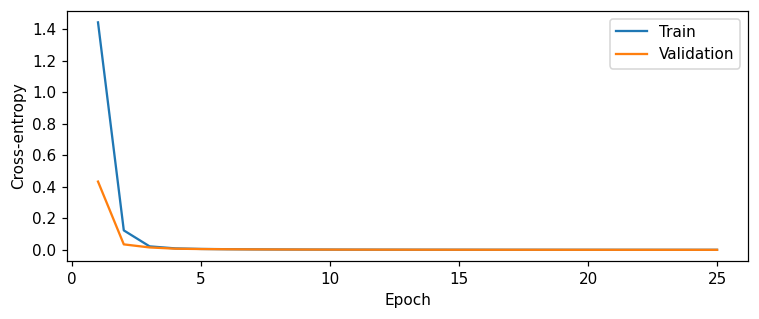

In [17]:
model, history, model_info = train(layers=2)
display(pd.DataFrame([model_info]).round({'Training seconds': 1}))
fig, ax = plt.subplots(figsize=(7, 3))
for name, values in history.items():
    ax.plot(range(1, EPOCHS + 1), values, label=name.title())
ax.set(xlabel='Epoch', ylabel='Cross-entropy')
ax.legend()
plt.tight_layout()
plt.show()


## 8. Translate new sentences

Generation starts from `<bos>` and appends the most likely token until `<eos>`. The decoder receives its own previous predictions, so an early mistake can affect the rest of a sentence.

We report **exact translation accuracy**, including a correctly placed `<eos>`. Both test sets contain 1,800 sentences with two adjectives: 1,200 without a location phrase and 600 with one. The second introduces one of six adjective–noun pairs excluded from training and validation, equally often as subject and object.


In [18]:
@torch.no_grad()
def generate(model, rows, max_new_tokens=16):
    model.eval()
    src, _, _ = collate(rows)
    src = src.to(device)
    memory = model.encode(src)
    prefix = torch.full((len(rows), 1), BOS, device=device, dtype=torch.long)
    finished = torch.zeros(len(rows), device=device, dtype=torch.bool)
    for _ in range(max_new_tokens):
        logits = model.decode(memory, prefix, src != PAD)
        next_ids = logits[:, -1].argmax(-1).masked_fill(finished, EOS)
        prefix = torch.cat([prefix, next_ids[:, None]], dim=1)
        finished |= next_ids == EOS
        if finished.all():
            break
    outputs = []
    for row in prefix[:, 1:].tolist():
        outputs.append(row[:row.index(EOS) + 1] if EOS in row else row)
    return outputs


def decode(ids):
    return ' '.join(tgt_vocab[i] for i in ids if i != EOS)


def evaluate(model, rows):
    outputs = []
    for start in range(0, len(rows), 128):
        outputs.extend(generate(model, rows[start:start + 128]))
    expected = [[*[tgt_ids[w] for w in row['target'].split()], EOS] for row in rows]
    correct = [out == gold for out, gold in zip(outputs, expected)]
    return sum(correct) / len(correct), outputs, correct


test_names = {'test_familiar': 'Familiar pairs, new sentences', 'test_new_pairs': 'New adjective–noun pairs'}


In [19]:
main_results, main_predictions, main_correct = [], {}, {}
for split, name in test_names.items():
    accuracy, outputs, correct = evaluate(model, splits[split])
    main_results.append({'Test': name, 'Sentences': len(outputs), 'Exact accuracy': accuracy})
    main_predictions[split], main_correct[split] = outputs, correct
display(pd.DataFrame(main_results).style.format({'Exact accuracy': '{:.1%}'}).hide(axis='index'))

grammar_results = []
for split, name in test_names.items():
    for has_location in (False, True):
        indices = [i for i, row in enumerate(splits[split]) if (' near ' in row['source']) == has_location]
        grammar_results.append({'Test': name, 'Pattern': 'With near' if has_location else 'Without near',
                                'Sentences': len(indices),
                                'Exact accuracy': sum(main_correct[split][i] for i in indices) / len(indices)})
display(pd.DataFrame(grammar_results).style.format({'Exact accuracy': '{:.1%}'}).hide(axis='index'))

examples = []
for split, name in test_names.items():
    for i in range(2):
        row = splits[split][i]
        examples.append({'Test': name, 'English': row['source'], 'Expected': row['target'],
                         'Generated': decode(main_predictions[split][i]), 'Exact': main_correct[split][i]})
    mistakes = [i for i, ok in enumerate(main_correct[split]) if not ok]
    if mistakes and mistakes[0] >= 2:
        i = mistakes[0]
        row = splits[split][i]
        examples.append({'Test': name, 'English': row['source'], 'Expected': row['target'],
                         'Generated': decode(main_predictions[split][i]), 'Exact': False})
display(pd.DataFrame(examples).style.hide(axis='index'))


Test,Sentences,Exact accuracy
"Familiar pairs, new sentences",1800,100.0%
New adjective–noun pairs,1800,100.0%


Test,Pattern,Sentences,Exact accuracy
"Familiar pairs, new sentences",Without near,1200,100.0%
"Familiar pairs, new sentences",With near,600,100.0%
New adjective–noun pairs,Without near,1200,100.0%
New adjective–noun pairs,With near,600,100.0%


Test,English,Expected,Generated,Exact
"Familiar pairs, new sentences",the green mouse likes the small horse,fim gami kel tik rali,fim gami kel tik rali,True
"Familiar pairs, new sentences",the red mouse finds the red dog,fim vek vok vek peko,fim vek vok vek peko,True
New adjective–noun pairs,the red fox follows the blue cat,dax vek nesh sul siva,dax vek nesh sul siva,True
New adjective–noun pairs,the green rabbit helps the big rabbit,tib gami tib boru tenu,tib gami tib boru tenu,True


## 9. Same words, different roles

These sentence pairs change who does what, or which adjective belongs to which noun, while keeping the same words. The last group also includes a location phrase. All adjective–noun combinations here were allowed in training, but these nine sentences were reserved for this experiment.

Read the expected and generated translations together. Correct vocabulary is only part of the task: the translator also needs to preserve the roles and adjective attachments.


In [20]:
for group in data['contrast_sets']:
    rows = group['examples']
    outputs = generate(model, rows)
    table = [{'Change': row['change'], 'English': row['source'], 'Expected': row['target'],
              'Generated': decode(out),
              'Exact': out == [*[tgt_ids[w] for w in row['target'].split()], EOS]}
             for row, out in zip(rows, outputs)]
    display(pd.DataFrame(table).style.hide(axis='index'))


Change,English,Expected,Generated,Exact
Original,the red cat sees the blue dog,nesh vek vok sul luma,nesh vek vok sul luma,True
Swap subject and object,the blue dog sees the red cat,vok sul nesh vek luma,vok sul nesh vek luma,True
Swap the adjectives,the blue cat sees the red dog,nesh sul vok vek luma,nesh sul vok vek luma,True


Change,English,Expected,Generated,Exact
Original,the small bird follows the quiet fox,mip tik dax nali siva,mip tik dax nali siva,True
Swap subject and object,the quiet fox follows the small bird,dax nali mip tik siva,dax nali mip tik siva,True
Swap the adjectives,the quiet bird follows the small fox,mip nali dax tik siva,mip nali dax tik siva,True


Change,English,Expected,Generated,Exact
Original,the green wolf helps the big mouse near the tree,zur gami fim boru tem na tenu,zur gami fim boru tem na tenu,True
Swap subject and object,the big mouse helps the green wolf near the tree,fim boru zur gami tem na tenu,fim boru zur gami tem na tenu,True
Swap the adjectives,the big wolf helps the green mouse near the tree,zur boru fim gami tem na tenu,zur boru fim gami tem na tenu,True


## 10. Follow the translation across the source

We use teacher forcing on one test sentence so each attention row has a known next-token label. Rows are decoder queries; columns are English source positions. The plots show the four cross-attention heads in the last decoder block, on the same 0–1 scale.

Compare the word order with where each head reads. The heads may distribute their weights differently. An attention map shows how values are mixed; it does not give a complete explanation of a prediction.


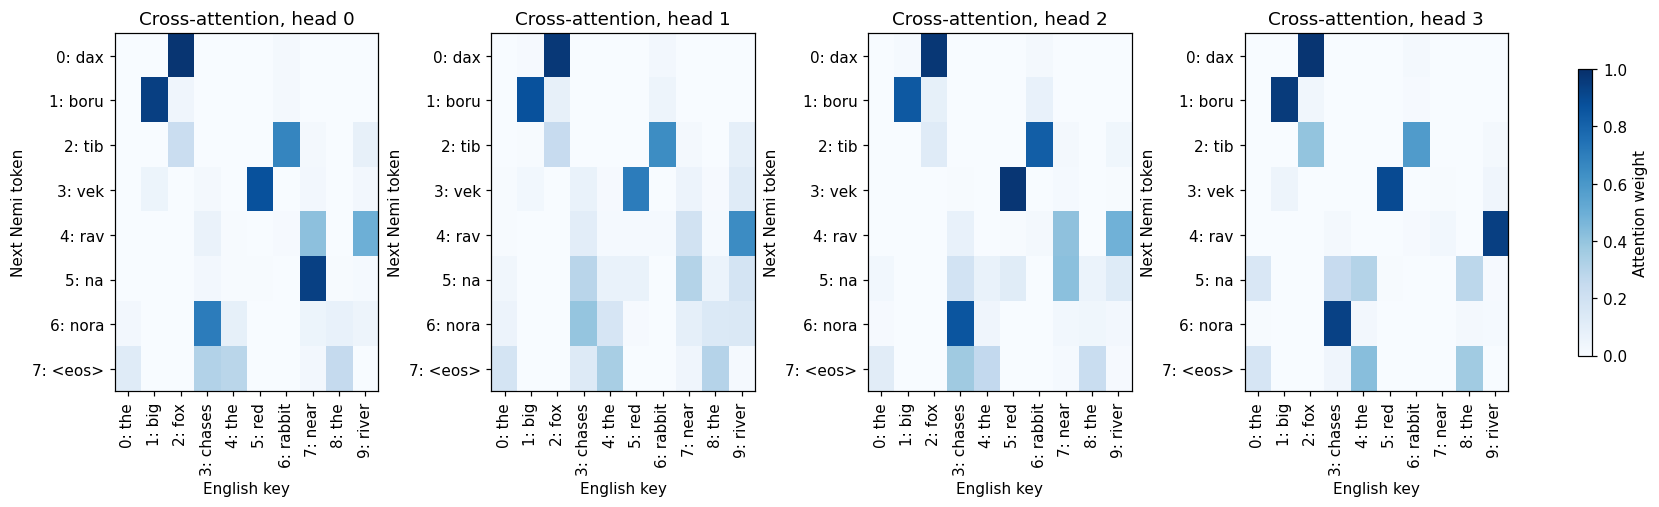

English: the big fox chases the red rabbit near the river
Nemi:    dax boru tib vek rav na nora


In [21]:
example = next(row for row in splits['test_familiar'] if ' near ' in row['source'])
src, tgt, gold = [x.to(device) for x in collate([example])]
with torch.no_grad():
    _, _, cross_weights = model.decode(model.encode(src), tgt, src != PAD, return_weights=True)

source_labels = [f'{i}: {src_vocab[j]}' for i, j in enumerate(src[0].tolist())]
target_labels = [f'{i}: {tgt_vocab[j]}' for i, j in enumerate(gold[0].tolist())]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), layout='constrained')
for head, ax in enumerate(axes):
    image = ax.imshow(cross_weights[0, head].cpu(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(source_labels)), source_labels, rotation=90)
    ax.set_yticks(range(len(target_labels)), target_labels)
    ax.set(title=f'Cross-attention, head {head}', xlabel='English key', ylabel='Next Nemi token')
fig.colorbar(image, ax=axes, shrink=0.8, label='Attention weight')
plt.show()
print('English:', example['source'])
print('Nemi:   ', example['target'])


## 11. Does another layer help?

Train a second translator with one block in each stack. Keep the data, width, heads, learning rate, batch order, and training updates fixed. Select each checkpoint by its validation loss, then compare test accuracy, parameter count, and training time.

The two-layer model has more parameters and does more computation per update. This is a comparison of two model sizes under the same update budget. Either may solve this language well; one run cannot establish that deeper models are generally better.


Epoch  1: train 1.841, validation 0.897
Epoch  2: train 0.505, validation 0.304
Epoch  3: train 0.183, validation 0.137
Epoch  4: train 0.092, validation 0.084
Epoch  5: train 0.062, validation 0.060
Epoch  6: train 0.044, validation 0.054
Epoch  7: train 0.037, validation 0.044
Epoch  8: train 0.032, validation 0.039
Epoch  9: train 0.031, validation 0.034
Epoch 10: train 0.025, validation 0.040
Epoch 11: train 0.023, validation 0.033
Epoch 12: train 0.024, validation 0.033
Epoch 13: train 0.023, validation 0.030
Epoch 14: train 0.020, validation 0.077
Epoch 15: train 0.017, validation 0.020
Epoch 16: train 0.014, validation 0.026
Epoch 17: train 0.014, validation 0.022
Epoch 18: train 0.016, validation 0.025
Epoch 19: train 0.013, validation 0.018
Epoch 20: train 0.010, validation 0.016
Epoch 21: train 0.011, validation 0.028
Epoch 22: train 0.013, validation 0.016
Epoch 23: train 0.011, validation 0.018
Epoch 24: train 0.010, validation 0.015
Epoch 25: train 0.009, validation 0.018


Layers per stack,Parameters,Best epoch,Training seconds,Familiar pairs,New pairs
1,"269,886",24,37.8,99.9%,73.0%
2,"531,006",25,60.2,100.0%,100.0%


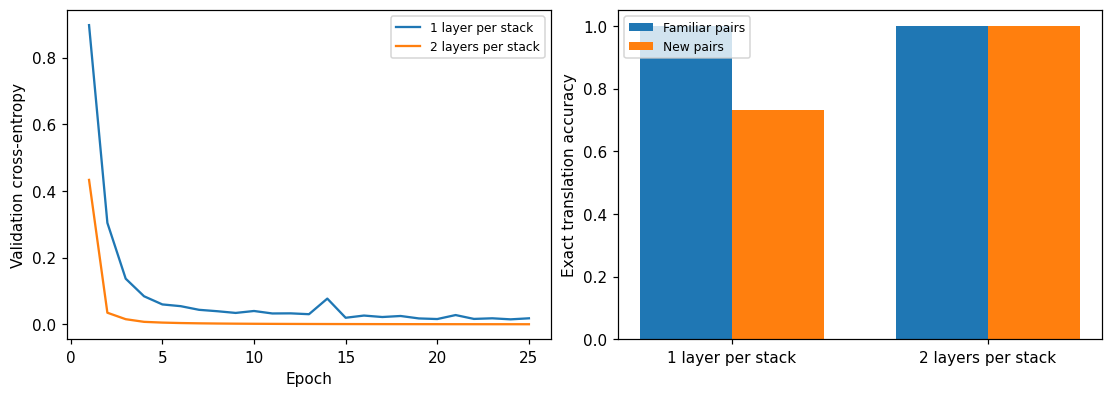

In [22]:
shallow, shallow_history, shallow_info = train(layers=1)
comparison = []
for net, info in [(shallow, shallow_info), (model, model_info)]:
    row = dict(info)
    if net is model:
        accuracies = [r['Exact accuracy'] for r in main_results]
    else:
        accuracies = [evaluate(net, splits[split])[0] for split in test_names]
    row['Familiar pairs'] = accuracies[0]
    row['New pairs'] = accuracies[1]
    comparison.append(row)
display(pd.DataFrame(comparison).style.format({
    'Familiar pairs': '{:.1%}', 'New pairs': '{:.1%}', 'Training seconds': '{:.1f}',
    'Parameters': '{:,}'
}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
for label, result in [('1 layer per stack', shallow_history), ('2 layers per stack', history)]:
    axes[0].plot(range(1, EPOCHS + 1), result['validation'], label=label)
axes[0].set(xlabel='Epoch', ylabel='Validation cross-entropy')
axes[0].legend(fontsize=8)
x = torch.arange(2).numpy()
for offset, key, label in [(-0.18, 'Familiar pairs', 'Familiar pairs'), (0.18, 'New pairs', 'New pairs')]:
    axes[1].bar(x + offset, [row[key] for row in comparison], width=0.36, label=label)
axes[1].set_xticks(x, ['1 layer per stack', '2 layers per stack'])
axes[1].set(ylabel='Exact translation accuracy', ylim=(0, 1.05))
axes[1].legend(fontsize=8)
plt.show()


## 12. A word with two meanings

**TODO 7 (15 points):** Choose an English word with two meanings and give each meaning a different Nemi translation. Design contexts that make the intended meaning clear.

You may use AI to generate additional sentence–translation pairs for your idea. Check that the examples and translations follow your rules. Around 4,000 new training examples is a suggested starting point; choose a size that suits your idea.

Retrain from scratch on the combined training data. Create a small held-out test set—around 200 examples, balanced between the meanings—including paired sentences where changing the context should change the translation. Show how reliably your word is translated in each meaning, a few generated examples, and performance on the original tests. The contexts, data design, and experiment are yours to choose.

You can reuse `build_vocab`, `train`, and `generate`. Rebuild the vocabularies from your updated training data before creating the new model.


In [23]:
import random
from itertools import product

lexicon = data["lexicon"]

bat_translations = {
    "animal": "zumi",
    "equipment": "paku"
}

extra_nouns = {
    "player": "navi",
    "coach": "kori",
    "athlete": "seni",
    "ball": "beli"
}

extra_locations = {
    "cave": "goru",
    "field": "fali"
}

# new equipment-related verbs + reusing some verbs already in the original lexicon
extra_verbs = {
    "hits": "doru",
    "strikes": "saku",
    "sends": "vemi",
    "knocks": "noku",
    "launches": "laki",
    "swings": "kava",
    "holds": "hopa",
    "carries": "mora",
    "uses": "yeka"
}

# existing and additional locations
locations = {
    **lexicon["locations"],
    **extra_locations
}

# existing adjectives + an option to use no adjective
adjectives = [(None, None)] + list(
    lexicon["adjectives"].items()
)

# existing animal nouns
animals = list(lexicon["nouns"].items())

# existing animal-related verbs
animal_verbs = list(lexicon["verbs"].items())

#### Helper functions

In [24]:
def english_np(noun, adjective):
    """Create an English noun phrase."""
    if adjective is None:
        return f"the {noun}"
    return f"the {adjective} {noun}"


def nemi_np(noun_translation, adjective_translation):
    """Create a Nemi noun phrase: noun followed by adjective."""
    if adjective_translation is None:
        return noun_translation
    return f"{noun_translation} {adjective_translation}"


def make_example(subject_en, subject_target,
                 verb_en, verb_target,
                 object_en, object_target,
                 location_en, location_target,
                 sense, role):

    source = (
        f"{subject_en} {verb_en} {object_en} "
        f"near the {location_en}"
    )

    target = (
        f"{subject_target} {object_target} "
        f"{location_target} na {verb_target}"
    )

    return {
        "source": source,
        "target": target,
        "sense": sense,
        "role": role
    }

In [25]:
# Generate animal-meaning examples

animal_subject_examples = []
animal_object_examples = []

for bat_adj, other_adj, animal, verb, location in product(
    adjectives,
    adjectives,
    animals,
    animal_verbs,
    locations.items()
):
    animal_en, animal_target = animal
    verb_en, verb_target = verb
    location_en, location_target = location

    # Case A: bat is the subject and means the animal
    animal_subject_examples.append(
        make_example(
            english_np("bat", bat_adj[0]),
            nemi_np(bat_translations["animal"], bat_adj[1]),
            verb_en,
            verb_target,
            english_np(animal_en, other_adj[0]),
            nemi_np(animal_target, other_adj[1]),
            location_en,
            location_target,
            "animal",
            "subject"
        )
    )

    # Case B: bat is the object and means the animal
    animal_object_examples.append(
        make_example(
            english_np(animal_en, other_adj[0]),
            nemi_np(animal_target, other_adj[1]),
            verb_en,
            verb_target,
            english_np("bat", bat_adj[0]),
            nemi_np(bat_translations["animal"], bat_adj[1]),
            location_en,
            location_target,
            "animal",
            "object"
        )
    )



# Generate animal-meaning examples

equipment_subject_examples = []
equipment_object_examples = []

equipment_subject_verbs = [
    ("hits", "doru"),
    ("strikes", "saku"),
    ("sends", "vemi"),
    ("knocks", "noku"),
    ("launches", "laki")
]

equipment_object_verbs = {
    **lexicon["verbs"],
    "swings": "kava",
    "holds": "hopa",
    "carries": "mora",
    "uses": "yeka"
}

actors = {
    **extra_nouns
}
actors.pop("ball")

for bat_adj, ball_adj, verb, location in product(
    adjectives,
    adjectives,
    equipment_subject_verbs,
    locations.items()
):
    verb_en, verb_target = verb
    location_en, location_target = location

    # Case C: bat is the subject and means the equipment
    equipment_subject_examples.append(
        make_example(
            english_np("bat", bat_adj[0]),
            nemi_np(bat_translations["equipment"], bat_adj[1]),
            verb_en,
            verb_target,
            english_np("ball", ball_adj[0]),
            nemi_np(extra_nouns["ball"], ball_adj[1]),
            location_en,
            location_target,
            "equipment",
            "subject"
        )
    )


for actor, actor_target in actors.items():
    for actor_adj, bat_adj, verb, location in product(
        adjectives,
        adjectives,
        equipment_object_verbs.items(),
        locations.items()
    ):
        verb_en, verb_target = verb

        # Case D: bat is the object and means the equipment
        equipment_object_examples.append(
            make_example(
                english_np(actor, actor_adj[0]),
                nemi_np(actor_target, actor_adj[1]),
                verb_en,
                verb_target,
                english_np("bat", bat_adj[0]),
                nemi_np(bat_translations["equipment"], bat_adj[1]),
                location[0],
                location[1],
                "equipment",
                "object"
            )
        )

#### Split each grammatical-role pool

In [26]:
def split_pool(examples, seed):
    examples = examples.copy()
    random.Random(seed).shuffle(examples)

    # 1,000 training + 100 validation + 50 test
    return (
        examples[:1000],
        examples[1000:1100],
        examples[1100:1150]
    )


animal_subj = split_pool(animal_subject_examples, 42)
animal_obj = split_pool(animal_object_examples, 43)

equipment_subj = split_pool(equipment_subject_examples, 44)
equipment_obj = split_pool(equipment_object_examples, 45)


def combine_splits(*pools):
    train = []
    validation = []
    test = []

    for pool in pools:
        train.extend(pool[0])
        validation.extend(pool[1])
        test.extend(pool[2])

    return train, validation, test


bat_train, bat_validation, bat_test = combine_splits(
    animal_subj,
    animal_obj,
    equipment_subj,
    equipment_obj
)

# shuffle the combined splits as well
random.Random(100).shuffle(bat_train)
random.Random(101).shuffle(bat_validation)
random.Random(102).shuffle(bat_test)

In [27]:
# Four deliberately held-out examples.
# They form two pairs: one animal/equipment pair
# with bat as subject, and another with bat as object.

paired_bat_examples = [
    {
        "source": "the bat chases the bird near the cave",
        "target": "zumi mip goru na nora",
        "sense": "animal",
        "role": "subject"
    },
    {
        "source": "the bat hits the ball near the field",
        "target": "paku beli fali na doru",
        "sense": "equipment",
        "role": "subject"
    },
    {
        "source": "the bird sees the bat near the cave",
        "target": "mip zumi goru na luma",
        "sense": "animal",
        "role": "object"
    },
    {
        "source": "the player swings the bat near the field",
        "target": "navi paku fali na kava",
        "sense": "equipment",
        "role": "object"
    }
]

# Prevent these exact sentences from appearing in training
# or validation, even if they were randomly generated there.
paired_sources = {x["source"] for x in paired_bat_examples}

bat_train = [
    x for x in bat_train if x["source"] not in paired_sources
]

bat_validation = [
    x for x in bat_validation if x["source"] not in paired_sources
]

# Keep 49 ordinary examples and add one deliberate example
# for each meaning/grammatical-role combination.
bat_test_original = bat_test.copy()
bat_test = []

for sense, role in [
    ("animal", "subject"),
    ("animal", "object"),
    ("equipment", "subject"),
    ("equipment", "object")
]:
    candidates = [
        x for x in bat_test_original
        if x["sense"] == sense and x["role"] == role
        and x["source"] not in paired_sources
    ]

    bat_test.extend(candidates[:49])

    paired = next(
        x for x in paired_bat_examples
        if x["sense"] == sense and x["role"] == role
    )
    bat_test.append(paired)

print("Final bat test size:", len(bat_test))


Final bat test size: 200


In [28]:
def model_pairs(examples):
    return [
        {
            "source": example["source"],
            "target": example["target"]
        }
        for example in examples
    ]


bat_train_pairs = model_pairs(bat_train)
bat_validation_pairs = model_pairs(bat_validation)
bat_test_pairs = model_pairs(bat_test)


# 7. Inspecting the generated dataset
print("Animal training examples:",
      sum(x["sense"] == "animal" for x in bat_train))

print("Equipment training examples:",
      sum(x["sense"] == "equipment" for x in bat_train))

print("Validation examples:", len(bat_validation))
print("Test examples:", len(bat_test))

print("\nSample examples:")

for example in bat_train[:10]:
    print("EN:", example["source"])
    print("NM:", example["target"])
    print("Sense:", example["sense"])
    print("Role:", example["role"])
    print()


Animal training examples: 2000
Equipment training examples: 1998
Validation examples: 400
Test examples: 200

Sample examples:
EN: the green cat finds the blue bat near the house
NM: nesh gami zumi sul ush na peko
Sense: animal
Role: object

EN: the small bat strikes the ball near the tree
NM: paku tik beli tem na saku
Sense: equipment
Role: subject

EN: the small bat strikes the red ball near the field
NM: paku tik beli vek fali na saku
Sense: equipment
Role: subject

EN: the red coach sees the green bat near the river
NM: kori vek paku gami rav na luma
Sense: equipment
Role: object

EN: the red dog likes the bat near the market
NM: vok vek zumi ket na rali
Sense: animal
Role: object

EN: the blue bird likes the quiet bat near the house
NM: mip sul zumi nali ush na rali
Sense: animal
Role: object

EN: the quiet coach carries the big bat near the river
NM: kori nali paku boru rav na mora
Sense: equipment
Role: object

EN: the big cat follows the small bat near the river
NM: nesh boru z

In [29]:
# checking that no complete source sentence appears in more than one of our new splits

train_sources = {x["source"] for x in bat_train}
val_sources = {x["source"] for x in bat_validation}
test_sources = {x["source"] for x in bat_test}

print("Train/validation overlap:",
      len(train_sources & val_sources))

print("Train/test overlap:",
      len(train_sources & test_sources))

print("Validation/test overlap:",
      len(val_sources & test_sources))

# checking that both meanings occur in every split
for name, split in [
    ("Train", bat_train),
    ("Validation", bat_validation),
    ("Test", bat_test)
]:
    print(
        name,
        {
            sense: sum(x["sense"] == sense for x in split)
            for sense in ["animal", "equipment"]
        }
    )

# checking that the generated source sentences are unique
print(
    "Unique training sentences:",
    len(train_sources),
    "/",
    len(bat_train)
)


Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
Train {'animal': 2000, 'equipment': 1998}
Validation {'animal': 200, 'equipment': 200}
Test {'animal': 100, 'equipment': 100}
Unique training sentences: 3998 / 3998


#### Combining the data and rebuilding the vocabulary

In [30]:
original_splits = dict(splits)

# combining original and additional training/validation data
augmented_train = original_splits["train"] + bat_train_pairs

augmented_validation = (
    original_splits["validation"] + bat_validation_pairs
)

# replacing only the training and validation splits (original sets remain untouched)
splits = {
    **original_splits,
    "train": augmented_train,
    "validation": augmented_validation
}

# rebuilding vocabularies using the augmented training set
src_vocab, tgt_vocab, src_ids, tgt_ids = build_vocab(
    splits["train"]
)

print("Training examples:", len(splits["train"]))
print("Validation examples:", len(splits["validation"]))
print("Bat test examples:", len(bat_test_pairs))

print("Animal translation in vocabulary:",
      "zumi" in tgt_ids)

print("Equipment translation in vocabulary:",
      "paku" in tgt_ids)


Training examples: 19998
Validation examples: 1800
Bat test examples: 200
Animal translation in vocabulary: True
Equipment translation in vocabulary: True


#### training the new model

In [31]:
model, bat_history, bat_model_info = train(layers=2)

display(pd.DataFrame([bat_model_info]).round(1))

Epoch  1: train 1.515, validation 0.290
Epoch  2: train 0.083, validation 0.033
Epoch  3: train 0.019, validation 0.013
Epoch  4: train 0.009, validation 0.008
Epoch  5: train 0.006, validation 0.005
Epoch  6: train 0.004, validation 0.004
Epoch  7: train 0.003, validation 0.003
Epoch  8: train 0.002, validation 0.002
Epoch  9: train 0.002, validation 0.002
Epoch 10: train 0.002, validation 0.002
Epoch 11: train 0.001, validation 0.001
Epoch 12: train 0.001, validation 0.001
Epoch 13: train 0.001, validation 0.001
Epoch 14: train 0.001, validation 0.001
Epoch 15: train 0.001, validation 0.001
Epoch 16: train 0.001, validation 0.001
Epoch 17: train 0.001, validation 0.001
Epoch 18: train 0.000, validation 0.000
Epoch 19: train 0.000, validation 0.000
Epoch 20: train 0.000, validation 0.000
Epoch 21: train 0.000, validation 0.000
Epoch 22: train 0.000, validation 0.000
Epoch 23: train 0.000, validation 0.000
Epoch 24: train 0.000, validation 0.000
Epoch 25: train 0.000, validation 0.000


,Layers per stack,Parameters,Best epoch,Training seconds
0,2,535823,25,75.0


#### evaluation

In [32]:
# evaluating the bat test set
bat_accuracy, bat_outputs, bat_correct = evaluate(
    model, bat_test_pairs
)

# checking whether the correct meaning was generated
sense_correct = []

for example, output in zip(bat_test, bat_outputs):
    predicted_words = [
        tgt_vocab[token]
        for token in output
        if token != EOS
    ]

    expected_bat = bat_translations[example["sense"]]

    sense_correct.append(expected_bat in predicted_words)

sense_accuracy = sum(sense_correct) / len(sense_correct)

print("Bat exact sentence accuracy:",
      f"{bat_accuracy:.2%}")

print("Bat sense accuracy:",
      f"{sense_accuracy:.2%}")


# evaluating the original test sets using the augmented model.
for split_name in ["test_familiar", "test_new_pairs"]:
    accuracy, _, _ = evaluate(
        model, original_splits[split_name]
    )

    print(f"{split_name}: {accuracy:.2%}")


# displaying some generated examples
for example, output in zip(bat_test[:8], bat_outputs[:8]):
    print("English:   ", example["source"])
    print("Expected:  ", example["target"])
    print("Generated: ", decode(output))
    print("Sense:     ", example["sense"])
    print()


Bat exact sentence accuracy: 100.00%
Bat sense accuracy: 100.00%
test_familiar: 100.00%
test_new_pairs: 100.00%
English:    the green bat finds the green wolf near the house
Expected:   zumi gami zur gami ush na peko
Generated:  zumi gami zur gami ush na peko
Sense:      animal

English:    the quiet bat sees the green bear near the field
Expected:   zumi nali bam gami fali na luma
Generated:  zumi nali bam gami fali na luma
Sense:      animal

English:    the red bat helps the quiet fox near the tree
Expected:   zumi vek dax nali tem na tenu
Generated:  zumi vek dax nali tem na tenu
Sense:      animal

English:    the big bat likes the big duck near the market
Expected:   zumi boru pon boru ket na rali
Generated:  zumi boru pon boru ket na rali
Sense:      animal

English:    the blue bat chases the red horse near the market
Expected:   zumi sul kel vek ket na nora
Generated:  zumi sul kel vek ket na nora
Sense:      animal

English:    the bat sees the green dog near the field
Expect